**Part C - Intensive margin and decomposition**

Follows the procedure of the Part B notebook: same data file, same transit groups, same income and children groups (fixed on 2024 characteristics), same controls, same clustering, same table style.

Two choices to state in the report (see the settings in the first code cell):
* `DAYS_RULE`: one car user in Lausanne 2025 reports 7.4 days per week, outside the 0-5 range of the data dictionary.
* `CENTRE_ON_CAR_USERS`: whether the interaction variables in Table C2 are centred on the car-user sample or on the Part B sample.

In [1]:
# packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

DATA_PATH = "parking_data_clean.csv"
TRANSIT_PATH = "transit_access.csv"

# ---- data decision --------------------------------------------------------------
# car_days_per_week must lie in [0, 5] (data dictionary). Values above 5 are invalid.
#   "cap"  : set them to 5 (keeps everybody in every sample, so Parts B and C use the same employees)
#   "drop" : remove that employee-year from every Part C calculation
#   "keep" : leave as is (not recommended)
DAYS_RULE = "cap"

# ---- table C2 settings ----------------------------------------------------------
CENTRE_ON_CAR_USERS = True   # True: interactions centred on the car-user sample; False: on the Part B sample
CENTRE_LOGFEE = False        # True: log(fee) is measured relative to the 2024 fee, which makes the main
                             # effects of the controls in column (d) interpretable at the baseline fee

raw = pd.read_csv(DATA_PATH)
ta = pd.read_csv(TRANSIT_PATH)

def prepare(raw, rule):
    """Same merge as Part B, plus the days rule and a car-user flag."""
    x = (raw.drop(columns=["transit_group", "transit_score"], errors="ignore")
            .merge(ta[["home_commune", "site", "transit_score", "transit_group"]],
                   on=["home_commune", "site"], how="left", validate="m:1"))
    bad = x["car_days_per_week"] > 5
    if rule == "cap":
        x.loc[bad, "car_days_per_week"] = 5.0
    elif rule == "drop":
        x = x[~bad]
    x = x.sort_values(["employee_id", "year"]).reset_index(drop=True)
    x["car_user"] = x["car_days_per_week"] > 0
    x["male"] = (x["gender"] == "M").astype(float)
    return x

df = prepare(raw, DAYS_RULE)

# ---- checks ---------------------------------------------------------------------
print("rows with car_days_per_week > 5 in the raw data:", int((raw["car_days_per_week"] > 5).sum()))
print("car users in the raw data with days <= 0:", int(((raw["uses_car"] == 1) & (raw["car_days_per_week"] <= 0)).sum()))
assert (df["car_user"] == (df["uses_car"] == 1)).all(), "car_days_per_week > 0 and uses_car disagree"
assert df["transit_group"].notna().all(), "some communes are missing from transit_access.csv"
print("rows:", len(df), "| car-user rows:", int(df["car_user"].sum()))

# fee change at Lausanne (the only site where the fee changed)
fee = df.groupby(["site", "year"])["parking_fee_chf"].first().unstack()
RATIO = fee.loc["Lausanne", 2025] / fee.loc["Lausanne", 2024]
LNR = np.log(RATIO)
print("Lausanne fee ratio:", RATIO)

rows with car_days_per_week > 5 in the raw data: 1
car users in the raw data with days <= 0: 0
rows: 2000 | car-user rows: 1022
Lausanne fee ratio: 2.0


In [2]:
# ---- table helpers (same look as Tables B1-B3) ----------------------------------
plt.rcParams.update({"font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"]})

def make_fmt(spec):
    """spec: column name -> format string; default 2 decimals."""
    def f(v, col):
        if pd.isna(v):
            return "–"
        if col == "p-value" and v < 0.001:
            return "<0.001"
        s = spec.get(col, "{:.2f}").format(v)
        if float(s) == 0:                      # avoid "-0.00"
            s = s.lstrip("-")
        return s.replace("-", "−")
    return f

def booktabs_panels(B, headers, title, note, fname, fmt, label_w=2.4, col_w=1.5, row_h=0.36):
    cols = list(B.columns)
    rows = []
    for p in dict.fromkeys(B.index.get_level_values(0)):
        if p != "Overall":
            rows.append(("panel", p, None))
        for g, r in B.loc[p].iterrows():
            rows.append(("overall" if p == "Overall" else "row", g, [fmt(r[c], c) for c in cols]))
    n_hdr = 2 * row_h
    width = label_w + col_w * len(cols)
    height = n_hdr + row_h * len(rows) + 1.4
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.7
    xc = lambda j: label_w + col_w * (j + 0.5)
    ax.text(width / 2, height - 0.25, title, ha="center", va="center", fontsize=12, weight="bold")
    for j, h in enumerate(headers):
        ax.text(xc(j), top - n_hdr / 2, h, ha="center", va="center", weight="bold", fontsize=10)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(top - n_hdr, 0, width, color="black", lw=0.7)
    y = top - n_hdr
    for k, (kind, label, vals) in enumerate(rows):
        yc = y - row_h / 2
        if kind == "panel":
            if k > 0:
                ax.hlines(y, 0, width, color="black", lw=0.4)
            ax.text(0.05, yc, label, ha="left", va="center", fontsize=10, style="italic", weight="bold")
        else:
            ax.text(0.05 if kind == "overall" else 0.3, yc, label, ha="left", va="center", fontsize=10)
            for j, v in enumerate(vals):
                ax.text(xc(j), yc, v, ha="center", va="center", fontsize=10)
        y -= row_h
    ax.hlines(y, 0, width, color="black", lw=1.6)
    ax.text(0, y - 0.3, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

def booktabs(t, title, fname, col_w=1.9, label_w=3.2, row_h=0.38, header_h=None,
             header_fs=10, body_fs=11, rule_after=()):
    """t = DataFrame of strings (same function as Table B1)."""
    n_rows, n_cols = t.shape
    widths = [col_w] * n_cols if np.isscalar(col_w) else list(col_w)
    xs = label_w + np.concatenate([[0], np.cumsum(widths)])
    width = xs[-1]
    header_h = header_h or row_h
    height = header_h + row_h * n_rows + 0.9
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.6
    body_top = top - header_h
    bottom = body_top - row_h * n_rows
    for j, c in enumerate(t.columns):
        ax.text((xs[j] + xs[j + 1]) / 2, top - header_h / 2, c, ha="center", va="center",
                weight="bold", fontsize=header_fs, linespacing=1.1)
    for i, (lab, row) in enumerate(t.iterrows()):
        y = body_top - row_h * (i + 0.5)
        ax.text(0.1, y, lab, ha="left", va="center", fontsize=body_fs)
        for j, v in enumerate(row):
            ax.text((xs[j] + xs[j + 1]) / 2, y, str(v), ha="center", va="center", fontsize=body_fs)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(body_top, 0, width, color="black", lw=0.7)
    ax.hlines(bottom, 0, width, color="black", lw=1.6)
    for k in rule_after:
        ax.hlines(body_top - row_h * k, 0, width, color="black", lw=0.4)
    ax.text(0, bottom - 0.3, "", fontsize=8)
    ax.text(width / 2, height - 0.2, title, ha="center", va="center", fontsize=12, weight="bold")
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

1. Compute the overall intensive elasticity from the change in mean driving days among car users. Then describe how this response differs by transit-accessibility group, income tercile, and number of children. State whether these are descriptive subgroup estimates or model-implied effects.

**Required output**: Table C1 with 2024 and 2025 mean car days among car users, intensive elasticity, and sample size for the full sample and each requested group.

In [3]:
# --- one row per employee, groups from 2024 characteristics (identical to Table B2) ---
d24 = df[df["year"] == 2024].set_index("employee_id")
d25 = df[df["year"] == 2025].set_index("employee_id")

emp = pd.DataFrame({
    "site": d24["site"],
    "car24": d24["uses_car"], "car25": d25["uses_car"],
    "days24": d24["car_days_per_week"], "days25": d25["car_days_per_week"],
    "income24": d24["gross_income_chf"],
    "n_children": d24["n_children"],
    "transit_group": d24["transit_group"],
    "transit_score": d24["transit_score"],
    "distance24": d24["distance_km"], "age24": d24["age"], "fte24": d24["fte"],
    "male24": d24["male"],
})

emp["transit_group"] = pd.Categorical(emp["transit_group"], categories=["Low", "Medium", "High"], ordered=True)
emp["income_tercile"] = pd.qcut(emp["income24"], 3, labels=["Low", "Middle", "High"])
emp["children_grp"] = emp["n_children"].map({0: "0", 1: "1", 2: "2+"})
emp["All"] = "All car users"

print(emp["income24"].quantile([1/3, 2/3]))      # must match Part B: 77,500 and 103,200

def c1_panel(gcol, label):
    L = emp[emp["site"] == "Lausanne"]
    out, idx = [], []
    for g, sub in L.groupby(gcol, observed=True):
        a = sub.loc[sub["car24"] == 1, "days24"].dropna()      # car users in 2024
        b = sub.loc[sub["car25"] == 1, "days25"].dropna()      # car users in 2025
        ma, mb = a.mean(), b.mean()
        el = np.log(mb / ma) / LNR
        se = np.sqrt(a.var(ddof=1) / (len(a) * ma**2) + b.var(ddof=1) / (len(b) * mb**2)) / LNR
        out.append({"Mean days 2024": ma, "Mean days 2025": mb, "Change (days)": mb - ma,
                    "Elasticity": el, "SE": se, "N 2024": len(a), "N 2025": len(b)})
        idx.append(str(g))
    o = pd.DataFrame(out)
    o.index = pd.MultiIndex.from_product([[label], idx])
    return o

C1 = pd.concat([c1_panel("All", "Overall"),
                c1_panel("transit_group", "Transit access"),
                c1_panel("income_tercile", "Income tercile"),
                c1_panel("children_grp", "Number of children")])
print(C1.round(3))

# Sion (fee unchanged): reference means only, no elasticity
S = df[(df["site"] == "Sion") & df["car_user"]].groupby("year")["car_days_per_week"].mean()
print("Sion car users, mean days:", S.round(3).to_dict())

0.333333     77500.0
0.666667    103200.0
Name: income24, dtype: float64
                                  Mean days 2024  Mean days 2025  \
Overall            All car users           3.604           3.453   
Transit access     Low                     3.263           3.013   
                   Medium                  3.865           3.738   
                   High                    3.498           3.293   
Income tercile     Low                     3.440           3.283   
                   Middle                  3.644           3.518   
                   High                    3.692           3.510   
Number of children 0                       3.262           2.926   
                   1                       3.544           3.478   
                   2+                      4.107           4.013   

                                  Change (days)  Elasticity     SE  N 2024  \
Overall            All car users         -0.151      -0.062  0.024     431   
Transit access     Low

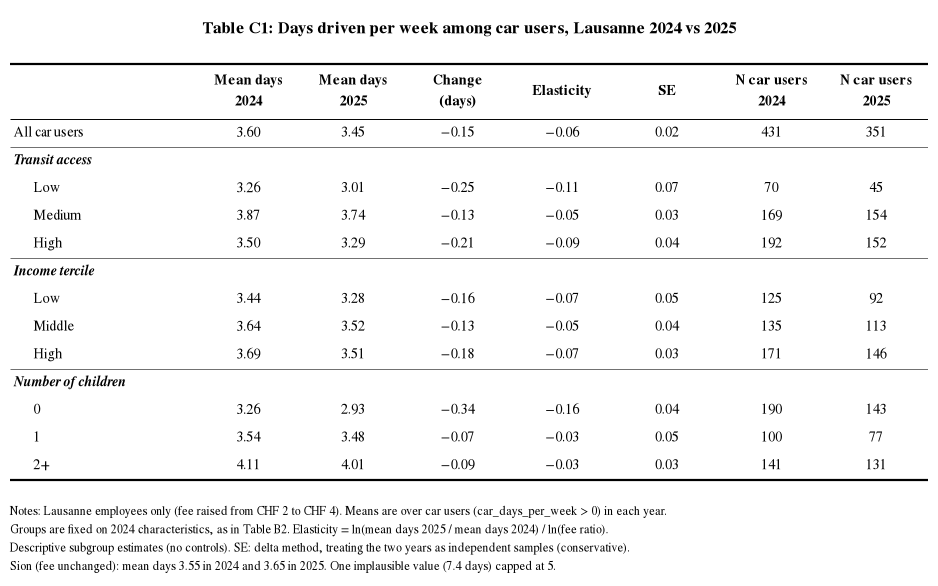

In [ ]:
# Table C1 (descriptive subgroup estimates)
headers = ["Mean days\n2024", "Mean days\n2025", "Change\n(days)", "Elasticity", "SE", "N car users\n2024", "N car users\n2025"]
fmt = make_fmt({"Change (days)": "{:+.2f}", "N 2024": "{:.0f}", "N 2025": "{:.0f}"})
note = (f"Notes: Lausanne employees only (fee raised from CHF {fee.loc['Lausanne', 2024]:.0f} to CHF {fee.loc['Lausanne', 2025]:.0f}). "
        "Means are over car users (car_days_per_week > 0) in each year.\n"
        "Groups are fixed on 2024 characteristics, as in Table B2. Elasticity = ln(mean days 2025 / mean days 2024) / ln(fee ratio).\n"
        "Descriptive subgroup estimates (no controls). SE: delta method, treating the two years as independent samples (conservative).\n"
        f"Sion (fee unchanged): mean days {S[2024]:.2f} in 2024 and {S[2025]:.2f} in 2025. "
        + ("One implausible value (7.4 days) capped at 5." if DAYS_RULE == "cap" else
           "One implausible value (7.4 days) dropped." if DAYS_RULE == "drop" else ""))
booktabs_panels(C1, headers, "Table C1: Days driven per week among car users, Lausanne 2024 vs 2025",
                note, "table_C1.png", fmt, label_w=2.4, col_w=1.35)

**Comment (C1)**

*To write:* the overall intensive elasticity (small compared with the extensive one in Table B2); which groups cut driving days most; that these are **descriptive subgroup estimates** (raw means, no controls) and not model-implied effects (those come from column (d) of Table C2); and the caveat that cell sizes are small in some groups and that the 2025 car users are a selected group (see C3).

2. Estimate equation (2) sequentially: Lausanne only; then with Sion; then with controls; and finally with controls and interactions. Use the same substantive logic as in Part B.

**Required output**: Table C2, a compact regression table with the four specifications. Report the policy coefficient in its native units and, where necessary, the corresponding elasticity. Include uncertainty, observations, R², and sample restrictions.

In [6]:
# --- estimation samples ---------------------------------------------------------
df["log_fee"] = np.log(df["parking_fee_chf"])
df["log_inc"] = np.log(df["gross_income_chf"])

need = ["uses_car", "log_fee", "site", "year", "transit_score", "log_inc",
        "n_children", "distance_km", "age", "gender", "fte"]          # same list as Table B3
d_all = df.dropna(subset=need).copy()                                 # Part B estimation sample (all employees)
d = d_all[d_all["car_user"]].copy()                                   # car users only
d["log_days"] = np.log(d["car_days_per_week"])
print("Part B sample:", len(d_all), "rows | car-user sample:", len(d), "rows |",
      "Lausanne:", int((d["site"] == "Lausanne").sum()), "| Sion:", int((d["site"] == "Sion").sum()))

# --- variables (same coding as Table B3) -----------------------------------------
ref = d if CENTRE_ON_CAR_USERS else d_all
d["inc10k_c"] = d["gross_income_chf"] / 1e4 - ref["gross_income_chf"].mean() / 1e4
d["score_c"] = d["transit_score"] - ref["transit_score"].mean()
d["kid1"] = (d["n_children"] == 1).astype(int)          # reference: 0 children
d["kid2"] = (d["n_children"] == 2).astype(int)          # 2 = "2 or more"
d["kid1_c"] = d["kid1"] - (ref["n_children"] == 1).mean()
d["kid2_c"] = d["kid2"] - (ref["n_children"] == 2).mean()
d["lf"] = d["log_fee"] - (np.log(fee.loc["Lausanne", 2024]) if CENTRE_LOGFEE else 0)

def fit(formula, data):
    # cluster by employee: each person appears in up to two years
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": data["employee_id"]})

ctrl = "score_c + inc10k_c + kid1 + kid2 + distance_km + age + C(gender) + fte"
m_a = fit("log_days ~ lf", d[d["site"] == "Lausanne"])                                        # Lausanne only
m_b = fit("log_days ~ lf + C(site) + C(year)", d)                                             # + Sion
m_c = fit(f"log_days ~ lf + C(site) + C(year) + {ctrl}", d)                                   # + controls
m_d = fit("log_days ~ lf + lf:score_c + lf:inc10k_c + lf:kid1_c + lf:kid2_c"
          f" + C(site) + C(year) + {ctrl}", d)                                                # + interactions
models = [m_a, m_b, m_c, m_d]

# elasticity (the coefficient itself) and implied change in days when the fee doubles
for name, m in zip("abcd", models):
    b, se = m.params["lf"], m.bse["lf"]
    print(f"({name}) elasticity {b:.3f} (SE {se:.3f}) -> doubling the fee changes days by {100*(RATIO**b-1):.1f}%   N={int(m.nobs)}  R2={m.rsquared:.3f}")

Part B sample: 1992 rows | car-user sample: 1022 rows | Lausanne: 782 | Sion: 240
(a) elasticity -0.077 (SE 0.015) -> doubling the fee changes days by -5.2%   N=782  R2=0.012
(b) elasticity -0.114 (SE 0.022) -> doubling the fee changes days by -7.6%   N=1022  R2=0.013
(c) elasticity -0.142 (SE 0.021) -> doubling the fee changes days by -9.4%   N=1022  R2=0.469
(d) elasticity -0.141 (SE 0.022) -> doubling the fee changes days by -9.3%   N=1022  R2=0.479


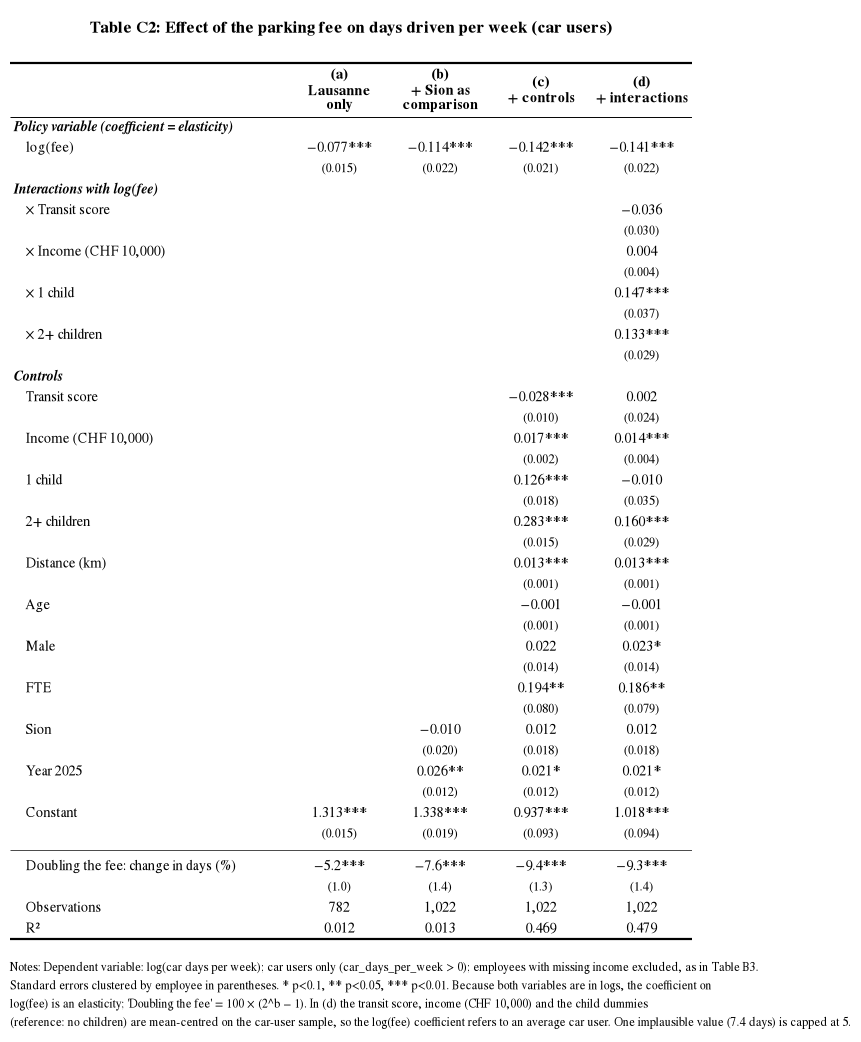

In [7]:
# Table C2 (same layout as Table B3)
def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .1 else ""

def cell(m, var):
    if var not in m.params.index:
        return "", ""
    b = f"{m.params[var]:.3f}{stars(m.pvalues[var])}"
    return b.replace("-", "−"), f"({m.bse[var]:.3f})"

sections = [
    ("Policy variable (coefficient = elasticity)", [("lf", "log(fee)")]),
    ("Interactions with log(fee)", [
        ("lf:score_c", "× Transit score"),
        ("lf:inc10k_c", "× Income (CHF 10,000)"),
        ("lf:kid1_c", "× 1 child"),
        ("lf:kid2_c", "× 2+ children")]),
    ("Controls", [
        ("score_c", "Transit score"), ("inc10k_c", "Income (CHF 10,000)"),
        ("kid1", "1 child"), ("kid2", "2+ children"),
        ("distance_km", "Distance (km)"), ("age", "Age"),
        ("C(gender)[T.M]", "Male"), ("fte", "FTE"),
        ("C(site)[T.Sion]", "Sion"), ("C(year)[T.2025]", "Year 2025"),
        ("Intercept", "Constant")]),
]

def build_rows(models):
    rows = []
    for sec, items in sections:
        rows.append(("section", sec, None))
        for var, lab in items:
            c = [cell(m, var) for m in models]
            rows.append(("coef", lab, [x[0] for x in c]))
            rows.append(("se", "", [x[1] for x in c]))
    rows.append(("rule", None, None))
    imp = [f"{100*(RATIO**m.params['lf']-1):.1f}{stars(m.pvalues['lf'])}".replace("-", "−") for m in models]
    imp_se = [f"({100*LNR*RATIO**m.params['lf']*m.bse['lf']:.1f})" for m in models]
    rows += [("coef", "Doubling the fee: change in days (%)", imp), ("se", "", imp_se),
             ("stat", "Observations", [f"{int(m.nobs):,}" for m in models]),
             ("stat", "R²", [f"{m.rsquared:.3f}" for m in models])]
    return rows

def c2_table(models, fname, title, headers, note, label_w=3.6, col_w=1.3, row_h=0.27, header_h=0.7):
    rows = build_rows(models)
    h = lambda k: 0.15 if k == "rule" else row_h
    body_h = sum(h(k) for k, _, _ in rows)
    width = label_w + col_w * len(models)
    height = header_h + body_h + 1.9
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.7
    xc = lambda j: label_w + col_w * (j + 0.5)
    ax.text(width / 2, height - 0.25, title, ha="center", va="center", fontsize=12, weight="bold")
    for j, t in enumerate(headers):
        ax.text(xc(j), top - header_h / 2, t, ha="center", va="center", weight="bold", fontsize=10, linespacing=1.1)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(top - header_h, 0, width, color="black", lw=0.7)
    y = top - header_h
    for kind, label, vals in rows:
        if kind == "rule":
            ax.hlines(y - 0.07, 0, width, color="black", lw=0.5)
        else:
            yc = y - row_h / 2
            if kind == "section":
                ax.text(0.05, yc, label, ha="left", va="center", fontsize=10, style="italic", weight="bold")
            else:
                ax.text(0.2, yc, label, ha="left", va="center", fontsize=10)
                for j, v in enumerate(vals):
                    ax.text(xc(j), yc, v, ha="center", va="center", fontsize=9 if kind == "se" else 10)
        y -= h(kind)
    ax.hlines(y, 0, width, color="black", lw=1.6)
    ax.text(0, y - 0.25, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

centre_txt = "the car-user sample" if CENTRE_ON_CAR_USERS else "the Part B sample (all employees)"
days_txt = {"cap": "One implausible value (7.4 days) is capped at 5.",
            "drop": "One implausible value (7.4 days) is dropped.", "keep": ""}[DAYS_RULE]
headers = ["(a)\nLausanne\nonly", "(b)\n+ Sion as\ncomparison", "(c)\n+ controls", "(d)\n+ interactions"]
note = ("Notes: Dependent variable: log(car days per week); car users only (car_days_per_week > 0); employees with missing income excluded, as in Table B3.\n"
        "Standard errors clustered by employee in parentheses. * p<0.1, ** p<0.05, *** p<0.01. Because both variables are in logs, the coefficient on\n"
        "log(fee) is an elasticity; 'Doubling the fee' = 100 × (2^b − 1). In (d) the transit score, income (CHF 10,000) and the child dummies\n"
        f"(reference: no children) are mean-centred on {centre_txt}, so the log(fee) coefficient refers to an average car user. " + days_txt)
c2_table(models, "table_C2.png", "Table C2: Effect of the parking fee on days driven per week (car users)", headers, note)

**Comment (C2)**

*To write:* the elasticity in each column (and the implied % change in days when the fee doubles); how adding Sion and the controls moves it; which interactions (if any) are significant and whether they match the subgroup pattern in Table C1. Keep the Sion comparison to the same short paragraph as in Part B, and add one reason for caution: the comparison group here is only the car users in Sion, and who is a car user changes with the fee (see C3).

3. Compare the estimates across specifications. Discuss selection into the car-user sample: is the average car user in 2025 the same kind of person as the average car user in 2024? Use descriptive evidence or covariate comparisons.

In [8]:
# --- comparison across specifications ---
cmp = pd.DataFrame({
    "elasticity": [m.params["lf"] for m in models],
    "SE": [m.bse["lf"] for m in models],
    "% change in days if fee doubles": [100 * (RATIO ** m.params["lf"] - 1) for m in models],
    "N": [int(m.nobs) for m in models],
}, index=["(a) Lausanne only", "(b) + Sion", "(c) + controls", "(d) + interactions"])
print(cmp.round(3))

                    elasticity     SE  % change in days if fee doubles     N
(a) Lausanne only       -0.077  0.015                           -5.216   782
(b) + Sion              -0.114  0.022                           -7.606  1022
(c) + controls          -0.142  0.021                           -9.373  1022
(d) + interactions      -0.141  0.022                           -9.294  1022


In [9]:
# --- selection: who is a car user in 2024 vs 2025? (Lausanne) ---
def welch(a, b):
    return stats.ttest_ind(a.dropna(), b.dropna(), equal_var=False).pvalue

def compare(g1, g2, spec):
    rows = {}
    for lab, col, scale in spec:
        x, y = g1[col] * scale, g2[col] * scale
        rows[lab] = {"Group 1": x.mean(), "Group 2": y.mean(), "Difference": y.mean() - x.mean(), "p-value": welch(x, y)}
    return pd.DataFrame(rows).T

# panel A: car users in 2024 vs car users in 2025
Lc = df[(df["site"] == "Lausanne") & df["car_user"]]
spec_df = [("Days per week", "car_days_per_week", 1), ("Distance (km)", "distance_km", 1),
           ("Income (CHF 10,000)", "gross_income_chf", 1e-4), ("Age", "age", 1),
           ("Children (mean)", "n_children", 1), ("Male (share)", "male", 1),
           ("FTE", "fte", 1), ("Transit score", "transit_score", 1)]
A = compare(Lc[Lc["year"] == 2024], Lc[Lc["year"] == 2025], spec_df)

# panel B: employees who drove in 2024: stayers (still drive in 2025) vs leavers
base = emp[(emp["site"] == "Lausanne") & (emp["car24"] == 1)]
stayers, leavers = base[base["car25"] == 1], base[base["car25"] == 0]
spec_emp = [("Days per week (2024)", "days24", 1), ("Distance (km)", "distance24", 1),
            ("Income (CHF 10,000)", "income24", 1e-4), ("Age", "age24", 1),
            ("Children (mean)", "n_children", 1), ("Male (share)", "male24", 1),
            ("FTE", "fte24", 1), ("Transit score", "transit_score", 1)]
Bp = compare(stayers, leavers, spec_emp)

joiners = emp[(emp["site"] == "Lausanne") & (emp["car24"] == 0) & (emp["car25"] == 1)]
print(f"Lausanne: {len(stayers)} stayers, {len(leavers)} leavers, {len(joiners)} joiners")

S1 = pd.concat({"A. Lausanne car users: 2024 (1) vs 2025 (2)": A,
                "B. Lausanne 2024 car users: stayers (1) vs leavers (2)": Bp})
print(S1.round(3))

Lausanne: 351 stayers, 80 leavers, 0 joiners
                                                                         Group 1  \
A. Lausanne car users: 2024 (1) vs 2025 (2)        Days per week           3.604   
                                                   Distance (km)          10.358   
                                                   Income (CHF 10,000)     9.993   
                                                   Age                    42.629   
                                                   Children (mean)         0.886   
                                                   Male (share)            0.508   
                                                   FTE                     0.972   
                                                   Transit score           0.361   
B. Lausanne 2024 car users: stayers (1) vs leav... Days per week (2024)    3.726   
                                                   Distance (km)          11.123   
                               

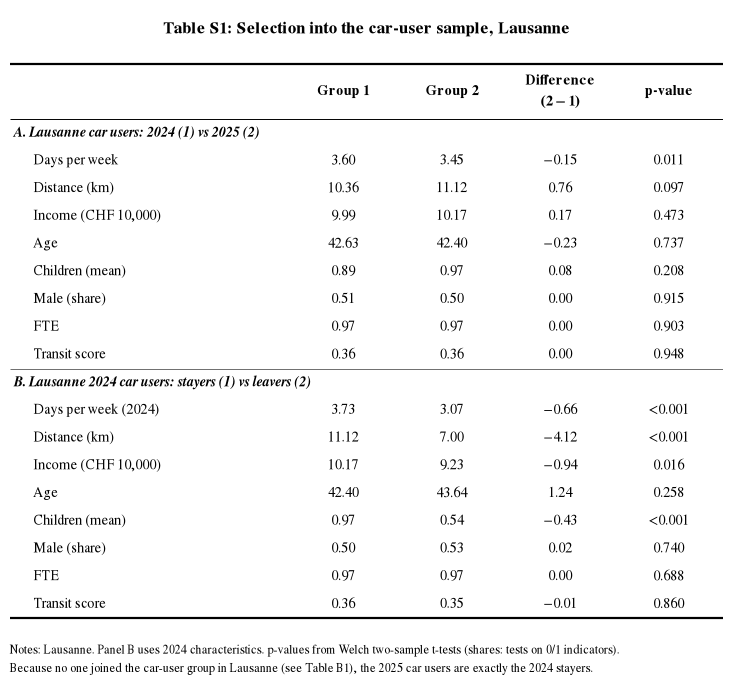

In [10]:
# Table S1 (supporting table for the selection discussion)
headers = ["Group 1", "Group 2", "Difference\n(2 − 1)", "p-value"]
fmt = make_fmt({"p-value": "{:.3f}"})
note = ("Notes: Lausanne. Panel B uses 2024 characteristics. p-values from Welch two-sample t-tests (shares: tests on 0/1 indicators).\n"
        "Because no one joined the car-user group in Lausanne (see Table B1), the 2025 car users are exactly the 2024 stayers.")
booktabs_panels(S1, headers, "Table S1: Selection into the car-user sample, Lausanne", note, "table_S1.png",
                fmt, label_w=3.6, col_w=1.4)

In [11]:
# --- within-person check: stayers only (removes selection on who stays) ---
def dlog(site):
    s = emp[(emp["site"] == site) & (emp["car24"] == 1) & (emp["car25"] == 1)]
    x = np.log(s["days25"]) - np.log(s["days24"])
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x)), len(x)

mL, seL, nL = dlog("Lausanne")
mS, seS, nS = dlog("Sion")
print(f"Lausanne stayers: mean change in log days {mL:.3f} (SE {seL:.3f}, n={nL}) -> elasticity {mL/LNR:.3f}")
print(f"Sion stayers (fee unchanged): mean change in log days {mS:.3f} (SE {seS:.3f}, n={nS})")
print(f"Within-person elasticity net of the Sion trend: {(mL-mS)/LNR:.3f} (SE {np.sqrt(seL**2+seS**2)/LNR:.3f})")
print(f"Raw Lausanne car-user elasticity, for comparison: {C1.loc[('Overall','All car users'), 'Elasticity']:.3f}")

Lausanne stayers: mean change in log days -0.089 (SE 0.008, n=351) -> elasticity -0.128
Sion stayers (fee unchanged): mean change in log days 0.023 (SE 0.011, n=117)
Within-person elasticity net of the Sion trend: -0.161 (SE 0.020)
Raw Lausanne car-user elasticity, for comparison: -0.062


**Comment (C3)**

*To write:* (i) how the four estimates in Table C2 compare; (ii) the answer to "is the 2025 car user the same kind of person?": using Table S1, say who left (their days, distance, income, children) and which way this composition change pushes the raw intensive estimate; (iii) the within-person check for stayers; (iv) the limitation that days are capped at 5 and many car users sit at 5.

4. Verify the decomposition using mutually consistent definitions and samples:

ε_total = ε_extensive + ε_intensive.

State which margin accounts for most of the total change.

**Required output**: Table C3 reporting the extensive, intensive, and total elasticities, together with the underlying means used in the calculation.

In [12]:
def decomposition(dfx, site="Lausanne"):
    """All three elasticities are log changes divided by the log fee change, on the same employees."""
    L = dfx[dfx["site"] == site]
    share = L.groupby("year")["car_user"].mean()                                   # car share
    dpu = L[L["car_user"]].groupby("year")["car_days_per_week"].mean()            # days per car user
    dpe = L.groupby("year")["car_days_per_week"].mean()                           # car days per employee (non-car = 0)
    lr = lambda s: np.log(s[2025] / s[2024])
    return {"share": share, "dpu": dpu, "dpe": dpe,
            "e_ext": lr(share) / LNR, "e_int": lr(dpu) / LNR, "e_tot": lr(dpe) / LNR}

D = decomposition(df)
# days per employee = car share x days per car user, so the identity holds exactly in logs
assert abs(D["e_ext"] + D["e_int"] - D["e_tot"]) < 1e-9
print({k: round(D[k], 3) for k in ["e_ext", "e_int", "e_tot"]})
print("share of the total change:", {k: f"{100*D[k]/D['e_tot']:.0f}%" for k in ["e_ext", "e_int"]})

{'e_ext': np.float64(-0.296), 'e_int': np.float64(-0.062), 'e_tot': np.float64(-0.358)}
share of the total change: {'e_ext': '83%', 'e_int': '17%'}


                              2024  2025 ln(2025/2024) Elasticity  \
Extensive: car share (%)      53.9  43.9        −0.205     −0.296   
Intensive: days per car user  3.60  3.45        −0.043     −0.062   
Total: car days per employee  1.94  1.51        −0.248     −0.358   
Extensive + intensive                                      −0.358   

                             Share of total  
Extensive: car share (%)                83%  
Intensive: days per car user            17%  
Total: car days per employee           100%  
Extensive + intensive                        


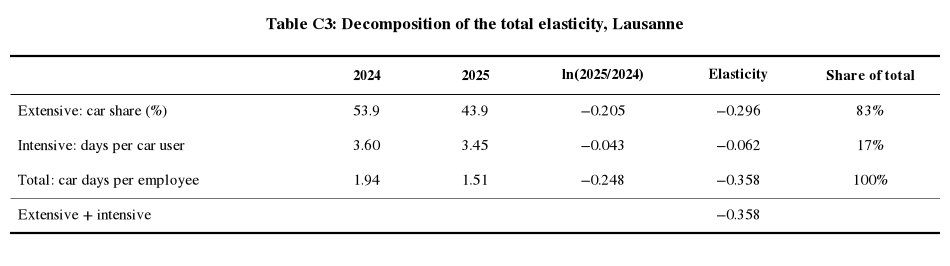

Notes: all elasticities = ln(2025 / 2024) / ln(fee ratio) on the same Lausanne employees; car days per employee = car share × days per car user (non-car commuters count as 0 days).


In [13]:
# Table C3
def row(label, s, scale=1, f="{:.2f}", e=None, share=None):
    return {"2024": f.format(s[2024] * scale), "2025": f.format(s[2025] * scale),
            "ln(2025/2024)": f"{np.log(s[2025] / s[2024]):.3f}".replace("-", "−"),
            "Elasticity": "" if e is None else f"{e:.3f}".replace("-", "−"),
            "Share of total": "" if share is None else f"{share:.0f}%"}

C3 = pd.DataFrame({
    "Extensive: car share (%)":            row("", D["share"], 100, "{:.1f}", D["e_ext"], 100 * D["e_ext"] / D["e_tot"]),
    "Intensive: days per car user":        row("", D["dpu"], 1, "{:.2f}", D["e_int"], 100 * D["e_int"] / D["e_tot"]),
    "Total: car days per employee":        row("", D["dpe"], 1, "{:.2f}", D["e_tot"], 100),
}).T
C3.loc["Extensive + intensive"] = ["", "", "", f"{D['e_ext'] + D['e_int']:.3f}".replace("-", "−"), ""]
print(C3)
booktabs(C3, "Table C3: Decomposition of the total elasticity, Lausanne",
         "table_C3.png", col_w=[1.4, 1.4, 1.9, 1.6, 1.8], label_w=3.9, row_h=0.45, header_h=0.5, rule_after=(3,))
print("Notes: all elasticities = ln(2025 / 2024) / ln(fee ratio) on the same Lausanne employees; "
      "car days per employee = car share × days per car user (non-car commuters count as 0 days).")

In [14]:
# robustness: the three ways of handling the implausible 7.4-day value
rob = {}
for rule in ["keep", "cap", "drop"]:
    Dx = decomposition(prepare(raw, rule))
    rob[rule] = {"extensive": Dx["e_ext"], "intensive": Dx["e_int"], "total": Dx["e_tot"],
                 "intensive share of total (%)": 100 * Dx["e_int"] / Dx["e_tot"]}
print(pd.DataFrame(rob).T.round(3))

      extensive  intensive  total  intensive share of total (%)
keep     -0.296     -0.059 -0.355                        16.608
cap      -0.296     -0.062 -0.358                        17.273
drop     -0.299     -0.064 -0.362                        17.585


**Comment (C4)**

*To write:* the three elasticities and the underlying means; that the identity holds exactly because all three are log changes on the same employees (days per employee = car share × days per car user); which margin accounts for most of the total change (the extensive margin); and that the result is not sensitive to how the 7.4-day value is handled (robustness cell above).